# Dia 2 - Disponibilização de dados para BI e Analytics
- Objetivos: apresentar como disponibilizar dados limpos e modelos para consumo de ferramentas como PowerBI, Tableu, Metabase e para uso em aprendizado de máquina. Além disso, tem como objetivo apresentar os conceitos de reverse ETL e governança de dados.

(Ana Julia e Luiza)
- Consumo por BI vs Ad-hoc
    - explorar as diferenças entre requisitoos recorrentes corporativos e análises exploratórias pontuais
- criação de visões analíticas no dw: CREATE VIEW e CREATE MATERIALIZED VIEW no duckDB para expor visões simplificadas da tabela fato e dimensões sem duplicar dados
https://www.w3schools.com/sql/sql_view.asp


- camada semântica / metrics layer
    - discutir sobre padronização de métricas de negócio em um único local
https://www.ibm.com/br-pt/think/topics/semantic-layer

- apresentar uma demonstração de utitlização das viewas criadas a partir de dashboards criados com pandas+matplotlib/plotly/seaborn


(Francisco e Fabrícia)
- disponibilização para ciência de dados e ML (feature store)
    - consumo para ML
        - ex: agregação histórica de comportamento de compra de clientes
    - feature store
        - https://www.databricks.com/br/blog/what-is-a-feature-store
    - exportação otimizada
        - https://www.datacamp.com/pt/tutorial/data-preparation-with-pandas
        - exportar como parquet e loading com pandas aplicando para um modelo do scikit-learn

- reverse elt
    - analytics passivo vs analytics operacional
    https://hightouch.com/blog/reverse-etl
    - paradigma reverse etl: dw como fonte para outras aplicações
    - discutir sobre boas práticas e cuidados ao elaborar os ciclos de auto alimentação com apis e outros serviços
    https://realpython.com/python-requests/


(daivik)
- governança, qualidade e contratos do serving
    - data trust
    - sla (service level agreement) e slo (service level objective)
        - prazos de entrega
        - metas de disponibilidade
        - pipelines de dados
    - data contracts

    - entrega: 
        - elaborar uma demonstração de como um data mart pode ser validado a partir do python, considerando métricas de nulidade ou limites aceitáveis
        - gerar casos de uso (sucesso e falha), emitindo um alerta de qualidade de dados em caso de falha na validação
    https://www.ibm.com/br-pt/think/topics/data-contract

## Consumo de Dados no Data Warehouse: BI, Análises Ad-hoc e Dashboards

Vamos utilizar o DuckDB para consultar o Data Warehouse, Pandas para organizar os resultados e Matplotlib para construir gráficos.

O banco de dados utilizado é o mesmo criado no notebook anterior. Por isso, não será necessário gerar novamente os dados nem reconstruir as tabelas dimensionais.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# Caminho do banco de dados criado no notebook anterior
caminho_dw = "modulo3-dados/data_warehouse.duckdb"

# Conecta ao banco de dados persistente
con = duckdb.connect(caminho_dw)

print("Conexão com o Data Warehouse realizada.")

Conexão com o Data Warehouse realizada.


### Conferindo as tabelas disponíveis
Antes de criar cisões, vamos conrferir se as tabelas fato e dimensoes estão disponíveis no banco de dados

In [2]:
# Lista as tabelas existentes no banco
display(con.execute("SHOW TABLES").df())

,name
0,dim_cliente
1,dim_data
2,dim_produto
3,fato_vendas
4,mart_comercial
5,mart_gestao
6,vendas_raw
7,vendas_tratadas


In [3]:
# Confere a estrutura da tabela fato
display(con.execute("DESCRIBE fato_vendas").df())

,column_name,column_type,null,key,default,extra
0,id_venda,BIGINT,YES,None,None,None
1,id_cliente,BIGINT,YES,None,None,None
2,id_produto,BIGINT,YES,None,None,None
3,id_data,INTEGER,YES,None,None,None
4,quantidade,BIGINT,YES,None,None,None
5,preco_unitario,BIGINT,YES,None,None,None
6,desconto,BIGINT,YES,None,None,None
7,valor_total,BIGINT,YES,None,None,None


In [4]:
# Confere a estrutura das dimensões
display(con.execute("DESCRIBE dim_cliente").df())
display(con.execute("DESCRIBE dim_produto").df())
display(con.execute("DESCRIBE dim_data").df())

,column_name,column_type,null,key,default,extra
0,id_cliente,BIGINT,YES,None,None,None
1,nome_cliente,VARCHAR,YES,None,None,None


,column_name,column_type,null,key,default,extra
0,id_produto,BIGINT,YES,None,None,None
1,nome_produto,VARCHAR,YES,None,None,None
2,categoria,VARCHAR,YES,None,None,None


,column_name,column_type,null,key,default,extra
0,id_data,INTEGER,YES,None,None,None
1,data_venda,DATE,YES,None,None,None
2,dia,BIGINT,YES,None,None,None
3,mes,BIGINT,YES,None,None,None
4,ano,BIGINT,YES,None,None,None


Perceba que:

- `fato_vendas`: registra os eventos de venda e seus valores;
- `dim_cliente`: contém informações dos clientes;
- `dim_produto`: contém os produtos e suas categorias;
- `dim_data`: organiza os atributos relacionados às datas das vendas.

A tabela fato contém as chaves que permitem relacionar cada venda às dimensões. Essas relações serão utilizadas para criar uma visão analítica mais simples de consultar.

## Consumo por BI vs. análises Ad-hoc

Os dados de um Data Warehouse podem ser utilizados de diferentes maneiras, de acordo com a necessidade de quem os consome.

### Consumo por Business Intelligence (BI)

O consumo por BI está relacionado ao acompanhamento recorrente de informações do negócio. É comum que gestores e equipes utilizem relatórios e dashboards para monitorar indicadores ao longo do tempo.

Exemplos de perguntas recorrentes:

- Qual foi o faturamento de cada mês?
- Qual categoria apresentou maior faturamento?
- Quantas vendas foram realizadas em cada mês?
- Como o faturamento está evoluindo?

Essas perguntas costumam ser respondidas periodicamente, utilizando critérios e definições padronizados.  Imagine que a empresa queira acompanhar o faturamento mensal em seu relatório de BI. A consulta abaixo agrupa as vendas por ano e mês.

In [5]:
sql_faturamento_mensal = """
SELECT
    d.ano,
    d.mes,
    SUM(f.valor_total) AS faturamento
FROM fato_vendas f
JOIN dim_data d
    ON f.id_data = d.id_data
GROUP BY
    d.ano,
    d.mes
ORDER BY
    d.ano,
    d.mes
"""

df_faturamento_mensal = con.execute(sql_faturamento_mensal).df()

display(df_faturamento_mensal)

,ano,mes,faturamento
0,2026,1,4970.0
1,2026,2,6995.0
2,2026,3,1560.0
3,2026,4,3550.0


Essa consulta pode ser utilizada repetidamente para alimentar um relatório mensal. A regra de cálculo e o agrupamento permanecem os mesmos; o que muda é o conjunto de dados disponível no Data Warehouse.

### Análises Ad-hoc

As análises Ad-hoc são consultas exploratórias realizadas para responder a uma necessidade específica. Elas não precisam fazer parte de um relatório recorrente.

Exemplos:

- Qual produto teve maior faturamento em determinado mês?
- Quais foram as cinco maiores vendas?
- Qual categoria teve maior quantidade de unidades vendidas em um período específico?

Uma análise Ad-hoc pode surgir de uma dúvida pontual e levar a novas perguntas durante a investigação. Considere uma pergunta pontual: **quais foram os cinco produtos com maior faturamento?**

A consulta é adaptada para responder diretamente a essa questão.

In [6]:
sql_top_produtos = """
SELECT
    p.nome_produto,
    p.categoria,
    SUM(f.valor_total) AS faturamento
FROM fato_vendas f
JOIN dim_produto p
    ON f.id_produto = p.id_produto
GROUP BY
    p.nome_produto,
    p.categoria
ORDER BY
    faturamento DESC
LIMIT 5
"""

df_top_produtos = con.execute(sql_top_produtos).df()

display(df_top_produtos)

,nome_produto,categoria,faturamento
0,Notebook,Eletrônicos,13600.0
1,Monitor,Eletrônicos,2900.0
2,Mouse,Acessórios,345.0
3,Teclado,Acessórios,230.0


Observe que a consulta Ad-hoc não precisa ser uma estrutura permanente. Ela foi escrita para responder a uma pergunta específica. Caso a pergunta mude, a consulta também pode mudar.

## Criação de visões analíticas no Data Warehouse

Conforme as análises se tornam mais frequentes, pode ser inconveniente escrever repetidamente consultas com os mesmos relacionamentos entre a tabela fato e as dimensões.

Uma alternativa é criar **views (visões)**. Uma view armazena a definição de uma consulta SQL e permite acessá-la como se fosse uma tabela, simplificandoa o acesso aos dados, mas não cria, por padrão, uma cópia física do resultado. Quando consultada, sua definição é executada sobre as tabelas de origem.

Vamos criar uma visão que reúne informações da tabela fato e das dimensões de cliente, produto e data., assim, as consultas posteriores poderão utilizar os campos de interesse sem repetir os mesmos `JOINs`.

In [7]:
sql_criar_view = """
CREATE OR REPLACE VIEW vw_vendas_analiticas AS
SELECT
    f.id_venda,
    f.id_cliente,
    c.nome_cliente,
    f.id_produto,
    p.nome_produto,
    p.categoria,
    f.id_data,
    d.data_venda,
    d.dia,
    d.mes,
    d.ano,
    f.quantidade,
    f.preco_unitario,
    f.desconto,
    f.valor_total
FROM fato_vendas f
JOIN dim_cliente c
    ON f.id_cliente = c.id_cliente
JOIN dim_produto p
    ON f.id_produto = p.id_produto
JOIN dim_data d
    ON f.id_data = d.id_data
"""

con.execute(sql_criar_view)

print("Visão vw_vendas_analiticas criada.")

Visão vw_vendas_analiticas criada.


### Consultando a view
Depois de criada a visão pode ser consultada com SELECT, assim como uma tebela

In [8]:
display(
    con.execute(
        "SELECT * FROM vw_vendas_analiticas LIMIT 10"
    ).df()
)

,id_venda,id_cliente,nome_cliente,id_produto,nome_produto,categoria,id_data,data_venda,dia,mes,ano,quantidade,preco_unitario,desconto,valor_total
0,1,101,Ana Silva,3,Notebook,Eletrônicos,20260110,2026-01-10,10,1,2026,1,3500,100,3400
1,2,102,Carlos Souza,2,Mouse,Acessórios,20260211,2026-02-11,11,2,2026,2,50,0,100
2,3,103,Mariana Lima,4,Teclado,Acessórios,20260312,2026-03-12,12,3,2026,1,120,10,110
3,4,101,Ana Silva,1,Monitor,Eletrônicos,20260113,2026-01-13,13,1,2026,1,1500,50,1450
4,5,104,João Santos,3,Notebook,Eletrônicos,20260214,2026-02-14,14,2,2026,2,3500,200,6800
5,6,105,Pedro Costa,2,Mouse,Acessórios,20260415,2026-04-15,15,4,2026,3,50,0,150
6,7,102,Carlos Souza,4,Teclado,Acessórios,20260116,2026-01-16,16,1,2026,1,120,0,120
7,8,106,Fernanda Alves,1,Monitor,Eletrônicos,20260317,2026-03-17,17,3,2026,1,1500,50,1450
8,9,107,Lucas Rocha,3,Notebook,Eletrônicos,20260418,2026-04-18,18,4,2026,1,3500,100,3400
9,10,108,Beatriz Mendes,2,Mouse,Acessórios,20260219,2026-02-19,19,2,2026,2,50,5,95


###  Utilizando a view em uma análise

Essa consulta calcula o faturamento por categoria utilizando a visão criada. Observe que não precisamos escrever novamente os relacionamentos entre fato e dimensões.

In [9]:
sql_faturamento_categoria = """
SELECT
    categoria,
    SUM(valor_total) AS faturamento,
    SUM(quantidade) AS unidades_vendidas
FROM vw_vendas_analiticas
GROUP BY categoria
ORDER BY faturamento DESC
"""

df_faturamento_categoria = con.execute(sql_faturamento_categoria).df()

display(df_faturamento_categoria)

,categoria,faturamento,unidades_vendidas
0,Eletrônicos,16500.0,6.0
1,Acessórios,575.0,9.0


###  Visão virtual e materialização

Uma view tradicional guarda a definição da consulta, e não uma cópia física dos resultados. Isso evita manter uma tabela duplicada apenas para disponibilizar uma consulta simplificada.

Em alguns bancos de dados existe o recurso `MATERIALIZED VIEW`, que armazena fisicamente o resultado da consulta. Isso pode ser útil quando uma consulta é custosa e seus resultados são reutilizados com frequência. Em contrapartida, o resultado armazenado precisa ser atualizado quando os dados de origem mudam.

#### Criando uma tabela com resultado materializado

In [10]:
sql_materializar_categoria = """
CREATE OR REPLACE TABLE resumo_vendas_categoria AS
SELECT
    categoria,
    SUM(valor_total) AS faturamento,
    SUM(quantidade) AS unidades_vendidas,
    COUNT(DISTINCT id_venda) AS total_vendas
FROM vw_vendas_analiticas
GROUP BY categoria
"""

con.execute(sql_materializar_categoria)

display(
    con.execute(
        "SELECT * FROM resumo_vendas_categoria ORDER BY faturamento DESC"
    ).df()
)

,categoria,faturamento,unidades_vendidas,total_vendas
0,Eletrônicos,16500.0,6.0,5
1,Acessórios,575.0,9.0,5


#### Atualizando a tabela materializada

Como a tabela foi criada a partir de uma consulta, seus valores representam o estado dos dados no momento da criação. Se as tabelas de origem forem alteradas, será necessário executar novamente a consulta de criação para reconstruir o resultado.

In [11]:
# Reexecuta a consulta de materialização para atualizar o resultado
con.execute(sql_materializar_categoria)

print("Tabela resumo_vendas_categoria reconstruída.")

Tabela resumo_vendas_categoria reconstruída.


## Camada semântica e Metrics Layer

Uma camada semântica organiza os conceitos de negócio utilizados nas análises. Seu objetivo é fazer com que diferentes usuários e ferramentas interpretem os dados de maneira consistente.

Um problema comum ocorre quando equipes diferentes calculam o mesmo indicador usando regras distintas. Por exemplo, um dashboard pode considerar faturamento como a soma do valor bruto das vendas, enquanto outro utiliza o valor após os descontos. Então, para evitar divergências, as definições das métricas devem ser documentadas e centralizadas.

### Criando uma visão com métricas padronizadas

Vamos criar uma visão que calcula os indicadores por ano, mês e categoria. Dessa forma, os dashboards e as consultas exploratórias podem reutilizar as mesmas definições.

In [12]:
sql_criar_metricas = """
CREATE OR REPLACE VIEW vw_metricas_vendas AS
SELECT
    ano,
    mes,
    categoria,
    SUM(valor_total) AS faturamento,
    COUNT(DISTINCT id_venda) AS quantidade_vendas,
    SUM(quantidade) AS unidades_vendidas,
    SUM(valor_total) /
        NULLIF(COUNT(DISTINCT id_venda), 0) AS ticket_medio
FROM vw_vendas_analiticas
GROUP BY
    ano,
    mes,
    categoria
"""

con.execute(sql_criar_metricas)

display(
    con.execute(
        "SELECT * FROM vw_metricas_vendas ORDER BY ano, mes, categoria"
    ).df()
)

,ano,mes,categoria,faturamento,quantidade_vendas,unidades_vendidas,ticket_medio
0,2026,1,Acessórios,120.0,1,1.0,120.0
1,2026,1,Eletrônicos,4850.0,2,2.0,2425.0
2,2026,2,Acessórios,195.0,2,4.0,97.5
3,2026,2,Eletrônicos,6800.0,1,2.0,6800.0
4,2026,3,Acessórios,110.0,1,1.0,110.0
5,2026,3,Eletrônicos,1450.0,1,1.0,1450.0
6,2026,4,Acessórios,150.0,1,3.0,150.0
7,2026,4,Eletrônicos,3400.0,1,1.0,3400.0


A visão `vw_metricas_vendas` centraliza as regras de cálculo utilizadas neste exemplo. Se um dashboard precisar apresentar o faturamento mensal por categoria, ele poderá consultar essa visão em vez de implementar novamente a fórmula.

Uma camada semântica completa pode oferecer recursos adicionais, como definições de dimensões, hierarquias, controle de acesso e integração com ferramentas de BI. Aqui estamos demonstrando o princípio de centralização das métricas usando recursos SQL do DuckDB.

## Consumo das visões com Python

Podemos utilizar Pandas para consultar as visões do Data Warehouse. O Pandas receberá os resultados das consultas SQL em DataFrames, que serão utilizados para montar visualizações, ou seja, a ferramenta de visualização não precisa acessar diretamente todas as tabelas do modelo dimensional. Ela pode consumir as visões analíticas preparadas no DW.

In [13]:
# Consulta as métricas padronizadas e transforma o resultado em DataFrame
df_metricas = con.execute(
    """
    SELECT *
    FROM vw_metricas_vendas
    ORDER BY ano, mes, categoria
    """
).df()

display(df_metricas.head())

,ano,mes,categoria,faturamento,quantidade_vendas,unidades_vendidas,ticket_medio
0,2026,1,Acessórios,120.0,1,1.0,120.0
1,2026,1,Eletrônicos,4850.0,2,2.0,2425.0
2,2026,2,Acessórios,195.0,2,4.0,97.5
3,2026,2,Eletrônicos,6800.0,1,2.0,6800.0
4,2026,3,Acessórios,110.0,1,1.0,110.0


### Preparando os dados para o gráfico mensal
Para evitar somar novamente vendas de diferentes categorias, vamos calcular o faturamento mensal diretamente a partir da visão detalhada.

In [14]:
df_mensal = con.execute(
    """
    SELECT
        ano,
        mes,
        SUM(valor_total) AS faturamento
    FROM vw_vendas_analiticas
    GROUP BY ano, mes
    ORDER BY ano, mes
    """
).df()

# Cria um rótulo para facilitar a leitura do eixo horizontal
df_mensal["periodo"] = (
    df_mensal["ano"].astype(str)
    + "-"
    + df_mensal["mes"].astype(str).str.zfill(2)
)

display(df_mensal)

,ano,mes,faturamento,periodo
0,2026,1,4970.0,2026-01
1,2026,2,6995.0,2026-02
2,2026,3,1560.0,2026-03
3,2026,4,3550.0,2026-04


O gráfico de linhas permite observar a evolução do faturamento ao longo dos meses.

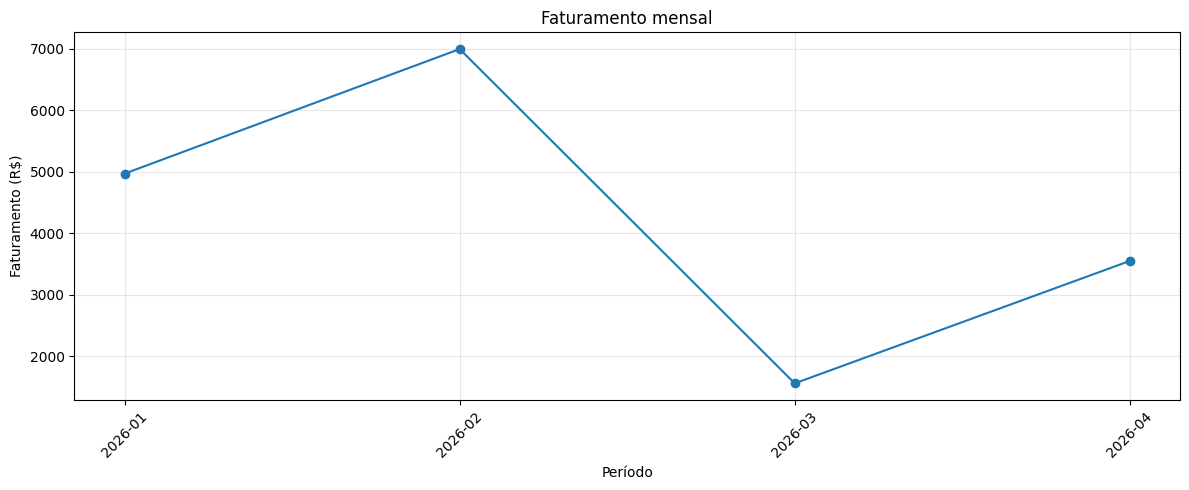

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_mensal["periodo"],
    df_mensal["faturamento"],
    marker="o"
)

plt.title("Faturamento mensal")
plt.xlabel("Período")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

É interessante também comparar o faturamento acumulado de cada categoria.

,categoria,faturamento
0,Eletrônicos,16500.0
1,Acessórios,575.0


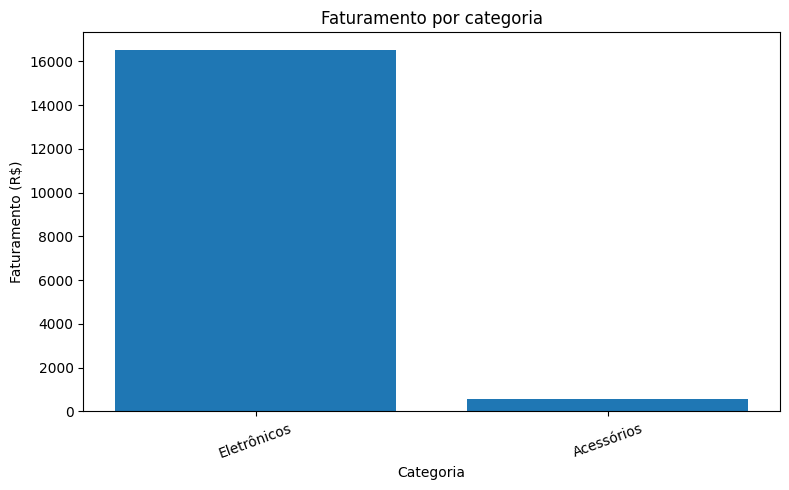

In [16]:
df_categoria = con.execute(
    """
    SELECT
        categoria,
        SUM(valor_total) AS faturamento
    FROM vw_vendas_analiticas
    GROUP BY categoria
    ORDER BY faturamento DESC
    """
).df()

display(df_categoria)

plt.figure(figsize=(8, 5))

plt.bar(
    df_categoria["categoria"],
    df_categoria["faturamento"]
)

plt.title("Faturamento por categoria")
plt.xlabel("Categoria")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Ou identificar quais produtos tiveram maior volume de unidades comercializadas.

,nome_produto,unidades_vendidas
0,Mouse,7.0
1,Notebook,4.0
2,Teclado,2.0
3,Monitor,2.0


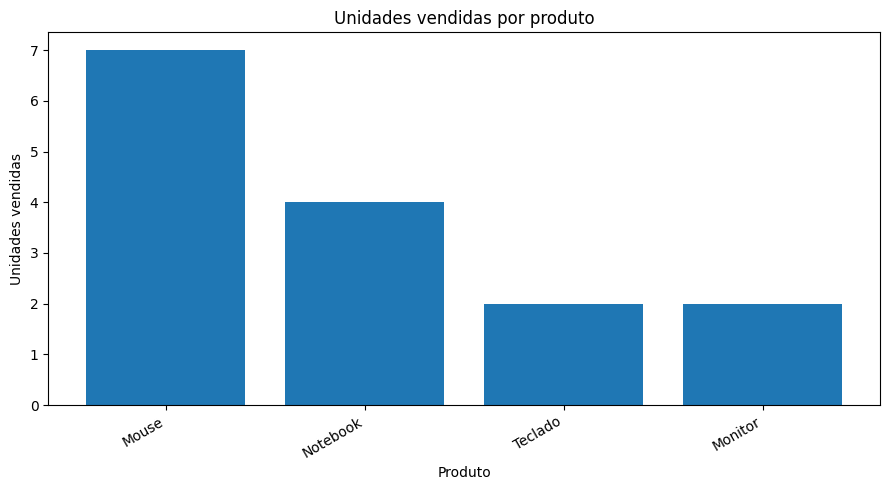

In [17]:
df_produtos = con.execute(
    """
    SELECT
        nome_produto,
        SUM(quantidade) AS unidades_vendidas
    FROM vw_vendas_analiticas
    GROUP BY nome_produto
    ORDER BY unidades_vendidas DESC
    """
).df()

display(df_produtos)

plt.figure(figsize=(9, 5))

plt.bar(
    df_produtos["nome_produto"],
    df_produtos["unidades_vendidas"]
)

plt.title("Unidades vendidas por produto")
plt.xlabel("Produto")
plt.ylabel("Unidades vendidas")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [18]:
con.close()

## Disponibilização de Dados para Ciência de Dados e Machine Learning (Feature Store)

> **Ideia central:** BI olha para o passado para apoiar decisões humanas; Machine Learning transforma o histórico em *features* numéricas estruturadas para prever o futuro.

Até aqui, disponibilizamos os dados do Data Warehouse para **BI e dashboards**, respondendo perguntas como *"quanto faturamos por mês?"* ou *"qual categoria vendeu mais?"*.

Quando quem consome os dados é um time de **Ciência de Dados e Machine Learning (ML)**, a necessidade muda: em vez de gráficos agregados por mês ou categoria, o modelo precisa de uma tabela com **uma linha por entidade** (por exemplo, um cliente) e **colunas numéricas que resumem seu comportamento histórico** — as chamadas ***features***.

| Aspecto | Consumo para BI / Analytics | Consumo para Ciência de Dados / ML |
|---|---|---|
| **Objetivo** | Explicar o que aconteceu (passado) | Prever o que vai acontecer (futuro) |
| **Granularidade típica** | Por mês, região ou categoria | Por entidade (`id_cliente`, `id_produto`) |
| **Quem consome** | Pessoas via dashboards (Power BI, Metabase) | Algoritmos (`scikit-learn`, PyTorch, etc.) |
| **Exemplo prático** | Faturamento mensal por categoria | Probabilidade de um cliente voltar a comprar no próximo mês |

Nesta seção vamos percorrer o fluxo completo de disponibilização para ML em três passos:
1. **Consumo para ML**: agregar o histórico de compras por cliente usando SQL no Data Warehouse.
2. **Feature Store**: entender como centralizar e reutilizar *features* (Offline vs. Online) e montar uma Feature Store local simplificada.
3. **Exportação otimizada**: exportar a tabela de *features* em **Parquet**, carregar seletivamente com **Pandas** e treinar um modelo de previsão com **Scikit-Learn**.

### 1. Consumo para ML: agregação histórica de comportamento de compra

Nossa tabela `fato_vendas` no Data Warehouse registra **uma linha por venda**. Um modelo que prevê comportamento de clientes não consegue usar essa tabela diretamente: primeiro precisamos consolidar o histórico de cada cliente em variáveis de comportamento — uma abordagem muito comum no mercado é o padrão **RFM** (**R**ecência, **F**requência e Valor **M**onetário).

A partir do nosso `data_warehouse.duckdb`, vamos calcular para cada cliente:
- `total_compras`: quantas compras o cliente fez (**frequência**);
- `gasto_total`: quanto gastou no total (**valor monetário**);
- `ticket_medio`: valor médio por compra;
- `total_itens`: quantidade total de unidades compradas;
- `desconto_medio`: desconto médio recebido nas compras;
- `dias_desde_ultima_compra`: há quantos dias foi a última compra (**recência**).

In [2]:
import duckdb
import pandas as pd

# Reconecta ao Data Warehouse criado no Módulo 3
con = duckdb.connect("modulo3-dados/data_warehouse.duckdb", read_only=True)
sql_features_clientes = """
SELECT
    c.id_cliente,
    c.nome_cliente,
    COUNT(f.id_venda) AS total_compras,
    SUM(f.valor_total) AS gasto_total,
    ROUND(AVG(f.valor_total), 2) AS ticket_medio,
    SUM(f.quantidade) AS total_itens,
    ROUND(AVG(f.desconto), 2) AS desconto_medio,
    DATEDIFF('day', CAST(MAX(d.data_venda) AS DATE), DATE '2026-05-01') AS dias_desde_ultima_compra
FROM fato_vendas f
JOIN dim_cliente c
    ON f.id_cliente = c.id_cliente
JOIN dim_data d
    ON f.id_data = d.id_data
GROUP BY
    c.id_cliente,
    c.nome_cliente
ORDER BY
    gasto_total DESC
"""
df_features_dw = con.execute(sql_features_clientes).df()
con.close()

display(df_features_dw)

,id_cliente,nome_cliente,total_compras,gasto_total,ticket_medio,total_itens,desconto_medio,dias_desde_ultima_compra
0,104,João Santos,1,6800.0,6800.0,2.0,200.0,76
1,101,Ana Silva,2,4850.0,2425.0,2.0,75.0,108
2,107,Lucas Rocha,1,3400.0,3400.0,1.0,100.0,13
3,106,Fernanda Alves,1,1450.0,1450.0,1.0,50.0,45
4,102,Carlos Souza,2,220.0,110.0,3.0,0.0,79
5,105,Pedro Costa,1,150.0,150.0,3.0,0.0,16
6,103,Mariana Lima,1,110.0,110.0,1.0,10.0,50
7,108,Beatriz Mendes,1,95.0,95.0,2.0,5.0,71


Repare na transformação: saímos de uma tabela de **eventos de venda** e chegamos a uma tabela com **1 linha por cliente** e colunas numéricas prontas para alimentar um modelo.

---

### 2. Feature Store

> **Ideia central:** uma **Feature Store** é um repositório centralizado para armazenar, documentar, versionar e servir *features* prontas — evitando retrabalho entre times e inconsistências entre treino e produção.

**O problema sem Feature Store:** imagine que o time de **Retenção** cria um notebook para calcular `ticket_medio` e `dias_desde_ultima_compra` para prever cancelamento (*churn*). No mesmo mês, o time de **Marketing** cria outro script para calcular as mesmas variáveis para recomendar ofertas — mas um time inclui compras com desconto e o outro não. Além do retrabalho, quando o modelo vai para produção, a aplicação acaba calculando a *feature* de um jeito ligeiramente diferente do treino (problema conhecido como ***training-serving skew***).

**A solução com Feature Store:** a engenharia de dados calcula e valida as *features* **uma única vez** e as publica em um catálogo centralizado. Qualquer cientista de dados pode descobrir e reutilizar essas *features* com a garantia de que a regra de cálculo é a mesma no treino e na produção.

Na prática, uma Feature Store costuma ter duas camadas complementares:

| Camada | Para que serve | Latência | Armazenamento típico | Exemplo de uso |
|---|---|---|---|---|
| **Offline Store** | Treinar modelos e gerar previsões em lote (*batch*) | Segundos a minutos | Arquivos **Parquet** / Delta Lake / Data Warehouse | Treinar um modelo de recompra com histórico de meses |
| **Online Store** | Servir previsões em tempo real | Milissegundos | Bancos chave-valor (Redis, DynamoDB) | Decidir um cupom de desconto no momento do *checkout* |

No mercado, ferramentas como **Databricks Feature Store**, **Feast** (*open source*), **AWS SageMaker Feature Store** e **Vertex AI Feature Store** implementam essa arquitetura.

> Referência recomendada: [Databricks — O que é uma Feature Store?](https://www.databricks.com/br/blog/what-is-a-feature-store)

#### Simulando uma Feature Store local (Offline)

No nosso Data Warehouse didático tínhamos apenas **8 clientes** — ótimo para visualizar a agregação SQL, mas muito pouco para treinar um modelo de Machine Learning.

Para demonstrar o fluxo completo de ponta a ponta, vamos gerar um histórico de vendas sintético com **200 clientes** (seguindo exatamente o mesmo formato do nosso DW), calcular as mesmas *features* de comportamento no DuckDB e salvar o resultado na nossa tabela de Feature Store offline (`fs_comportamento_cliente`).

Também incluímos a coluna alvo (`comprou_mes_seguinte`), que indica se o cliente voltou a comprar no mês seguinte (`1` = sim, `0` = não) — usando sempre o **comportamento passado** para prever um **evento futuro**.

In [7]:
import numpy as np
import pandas as pd
import duckdb

rng = np.random.default_rng(42)
n_clientes = 10000
data_referencia = pd.Timestamp("2026-05-01")

registros_vendas = []
targets = []

for id_cliente in range(1, n_clientes + 1):
    # Cada cliente realiza entre 1 e 12 compras nos últimos 90 dias
    qtd_compras = int(rng.integers(1, 13))
    dias_atras = rng.integers(1, 91, size=qtd_compras)

    for d in dias_atras:
        data_compra = (data_referencia - pd.Timedelta(days=int(d))).date()
        qtd_itens = int(rng.integers(1, 5))
        preco_unit = float(rng.choice([50, 120, 350, 1500, 3500], p=[0.30, 0.25, 0.20, 0.15, 0.10]))
        desconto = float(rng.choice([0, 10, 50, 100], p=[0.50, 0.25, 0.15, 0.10]))
        valor_total = max(preco_unit * qtd_itens - desconto, 20.0)

        registros_vendas.append({
            "id_cliente": id_cliente,
            "data_venda": data_compra,
            "quantidade": qtd_itens,
            "desconto": desconto,
            "valor_total": valor_total,
        })

    # Alvo futuro: clientes mais frequentes e recentes tendem a comprar novamente no mês seguinte
    recencia = int(dias_atras.min())
    score = 0.35 * qtd_compras - 0.04 * recencia - 1.6 + rng.normal(0, 0.8)
    targets.append({
        "id_cliente": id_cliente,
        "comprou_mes_seguinte": int(score > 0),
    })

df_historico = pd.DataFrame(registros_vendas)
df_targets = pd.DataFrame(targets)

# Usamos uma instância DuckDB em memória para construir a tabela da Feature Store
con_fs = duckdb.connect()

con_fs.execute("""
CREATE TABLE fs_comportamento_cliente AS
SELECT
    h.id_cliente,
    COUNT(*) AS total_compras,
    ROUND(SUM(h.valor_total), 2) AS gasto_total,
    ROUND(AVG(h.valor_total), 2) AS ticket_medio,
    SUM(h.quantidade) AS total_itens,
    ROUND(AVG(h.desconto), 2) AS desconto_medio,
    DATEDIFF('day', CAST(MAX(h.data_venda) AS DATE), DATE '2026-05-01') AS dias_desde_ultima_compra,
    t.comprou_mes_seguinte
FROM df_historico h
JOIN df_targets t
    ON h.id_cliente = t.id_cliente
GROUP BY
    h.id_cliente,
    t.comprou_mes_seguinte
ORDER BY
    h.id_cliente
""")

df_fs_preview = con_fs.execute("SELECT * FROM fs_comportamento_cliente LIMIT 5").df()
print(f"Total de clientes na Feature Store: {con_fs.execute('SELECT COUNT(*) FROM fs_comportamento_cliente').fetchone()[0]}")
display(df_fs_preview)

Total de clientes na Feature Store: 10000


,id_cliente,total_compras,gasto_total,ticket_medio,total_itens,desconto_medio,dias_desde_ultima_compra,comprou_mes_seguinte
0,1,2,6440.0,3220.00,3.0,30.00,59,0
1,2,2,1030.0,515.00,6.0,75.00,12,0
2,3,6,15830.0,2638.33,15.0,18.33,6,1
3,4,12,16190.0,1349.17,30.0,15.83,12,1
4,5,12,20780.0,1731.67,33.0,19.17,4,1


---

### 3. Exportação otimizada: Parquet + Pandas + Scikit-Learn

> **Ideia central:** para disponibilizar *features* para Ciência de Dados, o formato **Apache Parquet** é muito mais eficiente que CSV por ser **colunar**, **compacto** e **preservar os tipos de dados**.

| Característica | CSV | Parquet |
|---|---|---|
| **Orientação** | Por linha (texto puro) | Por coluna (binário) |
| **Tipos de dados** | Perdidos (tudo vira texto; Pandas precisa adivinhar ao ler) | Preservados no *schema* (`int64`, `float64`, `date`) |
| **Leitura seletiva** | Precisa ler o arquivo inteiro | Lê **apenas as colunas solicitadas** |
| **Tamanho em disco** | Maior | Bem menor (compressão colunar nativa) |

Vamos exportar nossa Feature Store diretamente do DuckDB para **Parquet** (e também para CSV apenas para comparar o tamanho dos arquivos).

> Referência recomendada: [DataCamp — Preparação de dados com Pandas](https://www.datacamp.com/pt/tutorial/data-preparation-with-pandas)

In [8]:
import os

pasta_fs = "modulo4-feature-store"
os.makedirs(pasta_fs, exist_ok=True)

caminho_parquet = os.path.join(pasta_fs, "fs_comportamento_cliente.parquet")
caminho_csv = os.path.join(pasta_fs, "fs_comportamento_cliente.csv")

# Exportação direta do DuckDB para Parquet e CSV
con_fs.execute(f"COPY fs_comportamento_cliente TO '{caminho_parquet}' (FORMAT PARQUET)")
con_fs.execute(f"COPY fs_comportamento_cliente TO '{caminho_csv}' (HEADER, DELIMITER ',')")
con_fs.close()

tam_parquet = os.path.getsize(caminho_parquet) / 1024
tam_csv = os.path.getsize(caminho_csv) / 1024

print(f"Arquivo Parquet salvo em: {caminho_parquet} ({tam_parquet:.2f} KB)")
print(f"Arquivo CSV salvo em:     {caminho_csv} ({tam_csv:.2f} KB)")

Arquivo Parquet salvo em: modulo4-feature-store\fs_comportamento_cliente.parquet (153.94 KB)
Arquivo CSV salvo em:     modulo4-feature-store\fs_comportamento_cliente.csv (331.65 KB)


#### Carregando o Parquet com Pandas e preparando os dados

Agora assumimos o papel do **Cientista de Dados** consumindo a Feature Store. Seguindo as boas práticas de preparação de dados com Pandas:
1. **Leitura colunar seletiva**: carregamos apenas as colunas que o modelo realmente vai usar (ignorando `id_cliente`, que é um identificador e não uma característica preditiva).
2. **Inspeção de tipos e valores nulos**: conferimos se os tipos foram preservados pelo Parquet e garantimos que não há valores ausentes.
3. **Separação de treino e teste**: separamos `X` (features) e `y` (alvo) em conjuntos de treino (75%) e teste (25%) para avaliar o modelo em dados que ele nunca viu.

In [10]:
from sklearn.model_selection import train_test_split

# 1. Leitura seletiva: carregamos apenas as features e o alvo (sem id_cliente)
features = [
    "total_compras",
    "gasto_total",
    "ticket_medio",
    "total_itens",
    "desconto_medio",
    "dias_desde_ultima_compra",
]
alvo = "comprou_mes_seguinte"

df_ml = pd.read_parquet(caminho_parquet, columns=features + [alvo])

# 2. Verificação de tipos (preservados pelo Parquet) e valores nulos
print("Tipos de dados carregados do Parquet:")
print(df_ml.dtypes)
print("\nValores nulos por coluna:")
print(df_ml.isna().sum())

# Tratamento defensivo de nulos (caso algum valor faltante apareça em futuras cargas)
df_ml[features] = df_ml[features].fillna(df_ml[features].median())

# 3. Separação em X (features) e y (alvo) + divisão treino/teste
X = df_ml[features]
y = df_ml[alvo]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=10, stratify=y
)

print(f"\nConjunto de treino: {len(X_train)} clientes | Conjunto de teste: {len(X_test)} clientes")
print("Proporção de recompra no dataset:")
print(y.value_counts(normalize=True).round(2))

Tipos de dados carregados do Parquet:
total_compras                 int64
gasto_total                 float64
ticket_medio                float64
total_itens                 float64
desconto_medio              float64
dias_desde_ultima_compra      int64
comprou_mes_seguinte          int64
dtype: object

Valores nulos por coluna:
total_compras               0
gasto_total                 0
ticket_medio                0
total_itens                 0
desconto_medio              0
dias_desde_ultima_compra    0
comprou_mes_seguinte        0
dtype: int64

Conjunto de treino: 7500 clientes | Conjunto de teste: 2500 clientes
Proporção de recompra no dataset:
comprou_mes_seguinte
1    0.54
0    0.46
Name: proportion, dtype: float64


#### Treinando e avaliando um modelo com Scikit-Learn

Vamos montar um **`Pipeline`** do `scikit-learn` combinando duas etapas:
1. **`StandardScaler`**: coloca todas as *features* na mesma escala (por exemplo, `gasto_total` varia na casa dos milhares, enquanto `total_compras` varia de 1 a 12).
2. **`LogisticRegression`**: modelo clássico, rápido e interpretável para classificação binária (prevê a probabilidade de o cliente comprar no próximo mês).

Usar um `Pipeline` garante que a padronização aprenda a média e o desvio padrão **apenas nos dados de treino**, evitando vazamento de dados (*data leakage*).

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Pipeline: padronização de escala + modelo de classificação
modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("classificador", LogisticRegression(random_state=42)),
])

# Treinamento
modelo.fit(X_train, y_train)

# Avaliação nos dados de teste
y_pred = modelo.predict(X_test)
acuracia = accuracy_score(y_test, y_pred)

print(f"Acurácia no conjunto de teste: {acuracia:.1%}\n")
print("Relatório de classificação:")
print(classification_report(y_test, y_pred, target_names=["Não comprou", "Comprou"]))

# Pesos aprendidos pelo modelo (interpretabilidade)
pesos = pd.Series(
    modelo.named_steps["classificador"].coef_[0],
    index=features,
).sort_values(ascending=False)

print("Influência de cada feature na probabilidade de recompra:")
display(pesos.round(3).to_frame(name="peso_modelo"))

Acurácia no conjunto de teste: 87.4%

Relatório de classificação:
              precision    recall  f1-score   support

 Não comprou       0.87      0.85      0.86      1156
     Comprou       0.88      0.89      0.88      1344

    accuracy                           0.87      2500
   macro avg       0.87      0.87      0.87      2500
weighted avg       0.87      0.87      0.87      2500

Influência de cada feature na probabilidade de recompra:


,peso_modelo
total_compras,2.595
gasto_total,0.104
desconto_medio,0.004
ticket_medio,-0.017
total_itens,-0.032
dias_desde_ultima_compra,-1.511


Repare nos pesos aprendidos: **`total_compras` tem peso positivo** (quanto mais frequente o cliente, maior a chance de recompra) e **`dias_desde_ultima_compra` tem peso negativo** (quanto mais tempo sem comprar, menor a chance de voltar).

Para fechar a demonstração, vamos simular o modelo fazendo uma **previsão para dois clientes novos** usando exatamente o mesmo conjunto de *features* da nossa Feature Store:

In [12]:
novos_clientes = pd.DataFrame([
    {
        "perfil": "Cliente Engajado (frequente e recente)",
        "total_compras": 10,
        "gasto_total": 6500.0,
        "ticket_medio": 650.0,
        "total_itens": 22,
        "desconto_medio": 25.0,
        "dias_desde_ultima_compra": 5,
    },
    {
        "perfil": "Cliente Inativo (poucas compras e antigo)",
        "total_compras": 1,
        "gasto_total": 120.0,
        "ticket_medio": 120.0,
        "total_itens": 1,
        "desconto_medio": 0.0,
        "dias_desde_ultima_compra": 75,
    },
])

probabilidades = modelo.predict_proba(novos_clientes[features])[:, 1]
novos_clientes["prob_recompra"] = (probabilidades * 100).round(1).astype(str) + "%"

display(novos_clientes[["perfil", "total_compras", "dias_desde_ultima_compra", "prob_recompra"]])

,perfil,total_compras,dias_desde_ultima_compra,prob_recompra
0,Cliente Engajado (frequente e recente),10,5,97.4%
1,Cliente Inativo (poucas compras e antigo),1,75,0.0%


#### Resumo do fluxo de disponibilização para ML

```
Data Warehouse (DuckDB)
   └─► Agregação SQL por entidade (comportamento histórico do cliente)
          └─► Feature Store Offline (exportação otimizada em Parquet)
                 └─► Leitura seletiva e preparação (Pandas)
                        └─► Treino e previsão (Scikit-Learn)
```

Com isso, o time de Engenharia de Dados entrega um **ativo reutilizável, rápido e confiável**, permitindo que o time de Ciência de Dados foque em modelagem e negócio em vez de gastar 80% do tempo limpando e recalculando dados brutos.

## Governança, qualidade e contratos do serving

> **Ideia central:** dado só tem valor se quem usa acredita nele.

**Exemplo:** uma rede de lojas tem um dashboard de vendas que a diretoria abre toda segunda de manhã. Numa segunda, o dashboard mostra que as vendas da região Sudeste **caíram 40%**. A diretoria entra em pânico e cogita cortar o orçamento de marketing da região. Duas horas depois, alguém descobre que as vendas não caíram: uma das lojas passou a enviar a região como **"SE"** em vez de **"Sudeste"**, e o dashboard não contou essas vendas. O erro foi corrigido no mesmo dia, mas na segunda seguinte o diretor pergunta: *"Esse número está certo mesmo? Confirma com a planilha do financeiro antes."*

O maior estrago não foi o número errado, que foi corrigido rápido, e sim a **perda de confiança**. Confiança demora muito para ser construída e um único erro basta para perdê-la.

Até aqui vimos como **expor** os dados do DW: views para BI, métricas padronizadas, features para ML e reverse ETL. Falta uma pergunta importante: **o consumidor pode confiar nesse dado?**

Um dashboard bonito com números errados é pior do que não ter dashboard, porque decisões serão tomadas em cima dele. É isso que chamamos de **data trust** (confiança nos dados): a garantia de que o dado entregue está **correto, completo, atualizado e no formato combinado**.

A confiança depende de algumas dimensões de qualidade:

| Dimensão | Pergunta que responde | Exemplo de falha |
|---|---|---|
| **Completude** | Tem dado faltando? | `ticket_medio` nulo em várias linhas |
| **Validade** | Os valores fazem sentido? | Receita negativa |
| **Consistência** | Segue o padrão combinado? | Região `"SE"` em vez de `"Sudeste"` |
| **Unicidade** | Tem registro duplicado? | Mesma região e dia aparecendo duas vezes |
| **Atualidade** (*freshness*) | O dado chegou no prazo? | Dashboard de hoje mostrando dados de 4 dias atrás |
| **Volume** | Chegou a quantidade esperada? | Carga com 10 linhas quando o normal é 150 |

Nesta seção vamos:
1. Entender **SLA e SLO**, a forma de combinar prazos e metas com quem consome os dados.
2. Conhecer **data contracts**, o acordo formal entre quem produz e quem consome um dado.
3. Construir em Python um **validador de data mart** baseado em contrato, com um caso de **sucesso** e um caso de **falha** que emite um **alerta de qualidade**.

### SLA e SLO

> **Ideia central:** SLA e SLO são a forma de transformar "o dado vai chegar logo" em uma promessa concreta e mensurável.

**Exemplo:** a diretora comercial pergunta ao time de dados: *"A que horas o dashboard de vendas fica pronto?"*. O time responde: *"Ah, de manhã cedo, geralmente."* Num dia, o dashboard só atualiza às 11h, e a diretora já tinha feito a reunião das 9h com números de dois dias atrás. Ela reclama, e o time responde: *"Mas a gente disse 'geralmente'..."*. Ninguém mentiu, mas também **ninguém combinou nada**: "de manhã cedo, geralmente" não dá para cobrar nem medir.

Esses termos vêm da engenharia de software (SRE) e foram adotados pela engenharia de dados:

| Sigla | Nome | O que é | Exemplo |
|---|---|---|---|
| **SLA** | *Service Level Agreement* | O **acordo** com o consumidor, com consequências se for quebrado | Dados de D-1 prontos até as 07:00 em **90%** dos dias; abaixo disso o time abre um incidente e comunica a diretoria |
| **SLO** | *Service Level Objective* | A **meta interna** do time | Dados de D-1 prontos até as 07:00 em **95%** dos dias |

Repare que o **SLO é mais rígido que o SLA**. Essa diferença funciona como margem de segurança: se o SLO começa a ser quebrado, o time percebe e corrige **antes** de violar o acordo com o cliente.

Para saber se as metas estão sendo cumpridas, o time **mede** o resultado real (por exemplo: "no último mês, o dado ficou pronto no prazo em 27 de 30 dias"). Esse número medido é chamado de **SLI** (*Service Level Indicator*).

Em dados, os SLAs normalmente cobrem três aspectos:
- **Prazos de entrega**: "os dados de ontem (D-1) estarão disponíveis até as 07:00".
- **Metas de disponibilidade**: "o DW estará acessível para consulta 99,5% do tempo no mês".
- **Pipelines de dados**: "pelo menos 98% das execuções diárias terminam com sucesso".

Ferramentas de orquestração como Airflow, Dagster e Prefect permitem configurar prazos e alertas para acompanhar essas metas de forma automática.

### Data contracts

> **Ideia central:** um data contract é um acordo escrito entre quem produz um dado e quem usa, dizendo exatamente o que o dado vai ter e quais garantias ele cumpre.

**Exemplo:** o time de engenharia de dados acha que o nome da coluna `receita_total` está confuso e a renomeia para `faturamento`. Tudo roda sem erro. No dia seguinte, o **dashboard comercial** mostra um campo vazio, o **modelo de previsão de vendas** do time de ciência de dados quebra e o **relatório do financeiro** para de atualizar. Ninguém agiu de má-fé: a engenharia nem sabia que esses três times usavam aquela coluna, porque **não havia nada escrito** dizendo isso.

Um **data contract** (contrato de dados) é um acordo **explícito e versionado** entre o **produtor** de um dado (o time de engenharia que mantém o data mart) e seus **consumidores** (dashboards, analistas, modelos de ML, sistemas via reverse ETL).

Sem contrato, cada consumidor "descobre" o formato do dado na prática, e qualquer mudança (renomear uma coluna, mudar um tipo) quebra algo em silêncio. Com contrato, o formato e as garantias ficam escritos e podem ser **verificados automaticamente**.

Um contrato costuma conter:
- **Identificação**: nome, versão, dono (quem acionar se der problema) e consumidores.
- **Schema**: colunas e tipos esperados.
- **Regras de qualidade**: limites de nulos, faixas de valores aceitáveis, valores permitidos, chaves únicas.
- **SLA**: atualidade máxima, volume mínimo e prazos de entrega.

Na prática, contratos são escritos em YAML ou JSON (há inclusive um padrão aberto, o *Open Data Contract Standard*) e verificados com ferramentas como **dbt tests**, **Great Expectations**, **Soda** ou **Pandera**. Aqui vamos representar o contrato como um dicionário Python e escrever o validador do zero, para entender o que essas ferramentas fazem por baixo dos panos.

### Demonstração: validando um data mart com Python

Agora vamos colocar em prática o que vimos: pegar uma tabela do data mart, conferir se ela respeita as regras combinadas no contrato e **emitir um alerta** caso alguma regra seja quebrada.

A demonstração tem quatro passos:
1. **A tabela do data mart**: a tabela que será entregue aos consumidores.
2. **As regras do contrato**: o que combinamos que o dado deve garantir.
3. **A validação**: o código que confere cada regra.
4. **O alerta**: o aviso emitido quando algo está errado.

Depois, testamos dois casos: uma tabela **correta** (sucesso) e uma tabela **com erros** (falha).

#### 1. A tabela do data mart

Este é o data mart de **Vendas**, usado pelo time comercial. Uma empresa costuma ter vários data marts (Financeiro, RH...), e **cada um tem o próprio contrato** com regras diferentes. Aqui vamos validar apenas o de Vendas.

No DW, este data mart é modelado em esquema estrela: uma tabela fato de vendas e dimensões como loja (que guarda a região de cada loja) e data. Além dessas tabelas, o data mart costuma ter **tabelas agregadas**: resumos já calculados, para que o dashboard não precise somar milhões de vendas a cada acesso.

A tabela abaixo é uma dessas tabelas agregadas. Ela é o resultado de uma **consulta** que junta cada venda com a sua loja (JOIN) e soma as vendas por região (GROUP BY). O pipeline roda essa consulta a cada carga e salva o resultado no data mart.

Um data mart, no geral, é validado **tabela por tabela**, cada uma com as próprias regras. Aqui mostramos o processo com esta tabela agregada, que é a que o dashboard recebe. A tabela fato e as dimensões seguiriam o mesmo processo.

No fluxo completo do curso, essa consulta seria feita no DW (por exemplo, no DuckDB). Aqui, para simplificar, vamos criar a tabela final diretamente com o pandas.

In [ ]:
import pandas as pd

data_mart = pd.DataFrame({
    "regiao":        ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"],
    "qtd_pedidos":   [120, 135, 110, 150, 140],
    "receita_total": [30000.0, 34000.0, 27500.0, 37000.0, 35000.0],
    "ticket_medio":  [250.0, 251.9, 250.0, 246.7, 250.0],
})

data_mart

#### 2. As regras do contrato

Este dicionário é uma versão simplificada do **data contract**: ele guarda as regras que combinamos com os consumidores do data mart.
- **Nulidade**: cada coluna pode ter no máximo 5% de valores vazios.
- **Limites aceitáveis**: a receita deve estar entre 0 e 1 milhão, e o ticket médio entre 1 e 5 mil.

In [ ]:
regras = {
    "max_nulos": 0.05,  # cada coluna pode ter no máximo 5% de valores vazios
    "limites": {
        "receita_total": (0, 1_000_000),
        "ticket_medio": (1, 5_000),
    },
}

#### 3. A validação

A função `validar` confere cada regra e devolve uma **lista de problemas** encontrados. Se a lista estiver vazia, o data mart passou em todas as regras.

In [ ]:
def validar(df, regras):
    problemas = []

    # Regra 1: nulidade
    for coluna in df.columns:
        pct_nulos = df[coluna].isna().mean()  # percentual de valores vazios na coluna
        if pct_nulos > regras["max_nulos"]:
            problemas.append(f"{coluna}: {pct_nulos:.0%} de valores vazios")

    # Regra 2: limites aceitáveis
    for coluna, (minimo, maximo) in regras["limites"].items():
        fora = df[(df[coluna] < minimo) | (df[coluna] > maximo)]  # linhas fora do intervalo
        if len(fora) > 0:
            problemas.append(f"{coluna}: {len(fora)} valor(es) fora do intervalo {minimo} a {maximo}")

    return problemas

#### 4. O alerta

A função `verificar_data_mart` roda a validação e decide: se não houver problemas, o data mart é aprovado; se houver, emite um **alerta de qualidade de dados** listando o que deu errado.

Aqui o alerta é apenas impresso na tela, mas em uma empresa ele seria enviado para o Slack, Teams ou e-mail do time responsável.

In [ ]:
def verificar_data_mart(df, regras):
    problemas = validar(df, regras)
    if not problemas:
        print("[OK] Data mart aprovado. Pode ser disponibilizado.")
    else:
        print("[ALERTA DE QUALIDADE DE DADOS] Data mart reprovado!")
        for problema in problemas:
            print("  -", problema)

#### Caso 1: data mart correto (sucesso)

O data mart que criamos respeita todas as regras, então deve ser aprovado.

In [ ]:
verificar_data_mart(data_mart, regras)

#### Caso 2: data mart com erros (falha)

Agora vamos simular dois problemas comuns na vida real:
- um **valor vazio** no ticket médio (uma integração deixou de enviar o campo);
- uma **receita negativa** (um bug no cálculo).

Fazemos uma cópia do data mart e "estragamos" esses valores.

In [ ]:
data_mart_com_erro = data_mart.copy()
data_mart_com_erro.loc[0, "ticket_medio"] = None       # valor vazio
data_mart_com_erro.loc[1, "receita_total"] = -5000.0   # receita negativa

verificar_data_mart(data_mart_com_erro, regras)

Repare que o alerta diz **exatamente o que está errado e em qual coluna**. Assim, o time responsável consegue investigar rápido, e o problema é descoberto **antes** de o dado chegar ao dashboard, e não pela diretoria.

Na vida real, as validações costumam incluir também outras regras, como duplicatas, valores permitidos e se o dado chegou no prazo. Ferramentas como **dbt tests**, **Great Expectations**, **Soda** e **Pandera** automatizam esse tipo de verificação.